# Workshop 1 — Source Profiling (Team 5: Extreme Weather Monitoring, Texas)

This notebook profiles the **real, unmodified samples** downloaded by
`workshop_1/scripts/fetch_samples.py` from the four project sources:

| # | Source | Role | Sample |
|---|--------|------|--------|
| H1 | NOAA Storm Events Database (yearly CSV.gz) | historical | all Texas rows of 2025 |
| H2 | GHCN-Daily via NCEI Access Data Service (JSON) | historical | 10 Texas first-order stations, 2025-01-01 → today |
| I1 | NWS API `/alerts` (GeoJSON / CAP) | incremental | Texas alerts, last ~7 days + active, two polls |
| I2 | NWS API `/stations/{id}/observations` (GeoJSON) | incremental | 10 stations, two polls |

For each source we report: volume, null percentage per field, value ranges, duplicated identifiers,
timestamp format and time zone, coordinate validity, and unit consistency. Then we list concrete
data-quality problems, cross-source overlap candidates, and the empirical update behaviour.

In [1]:
import json, re, sys, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.sources.raw_readers import read_storm_events, read_ghcn_daily_json, read_nws_folder
from src.normalization import canonical as C

SAMPLES = ROOT / "workshop_1" / "samples"
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CFG = yaml.safe_load((ROOT / "config" / "sources.yaml").read_text(encoding="utf-8"))
STATIONS = pd.DataFrame(CFG["region"]["stations"])
BBOX = CFG["region"]["bbox"]
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def latest(pattern, folder=SAMPLES):
    return sorted(p for p in Path(folder).glob(pattern) if not p.name.endswith(".headers.json"))[-1]

def profile(df, name):
    """Null % and distinct values per field."""
    prof = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "null_pct": (df.isna().mean() * 100).round(1),
        "n_distinct": df.astype(str).nunique(),
        "example": df.apply(lambda s: s.dropna().astype(str).iloc[0][:40] if s.notna().any() else None),
    })
    print(f"{name}: {len(df):,} records x {df.shape[1]} fields")
    return prof

def in_bbox(lat, lon, pad=0.5):
    return lat.between(BBOX["min_lat"] - pad, BBOX["max_lat"] + pad) & lon.between(BBOX["min_lon"] - pad, BBOX["max_lon"] + pad)
STATIONS

,nws_id,ghcn_id,name
0,KDFW,USW00003927,Dallas-Fort Worth Intl
1,KIAH,USW00012960,Houston Intercontinental
2,KAUS,USW00013904,Austin-Bergstrom Intl
3,KSAT,USW00012921,San Antonio Intl
4,KELP,USW00023044,El Paso Intl
5,KLBB,USW00023042,Lubbock Intl
6,KAMA,USW00023047,Amarillo Intl
7,KCRP,USW00012924,Corpus Christi Intl
8,KMAF,USW00023023,Midland Intl
9,KBRO,USW00012919,Brownsville South Padre Intl


## 1. H1 — NOAA Storm Events Database (bulk CSV)

File: `StormEvents_details-ftp_v1.0_d2025_c<compilation>.csv.gz` (full file kept in `data/raw/`,
Texas rows copied byte-for-byte into `workshop_1/samples/`).

In [2]:
se_path = latest("noaa_storm_events_TX_*.csv")
se = read_storm_events(se_path)
prof_se = profile(se, "Storm Events TX 2025")
prof_se.sort_values("null_pct", ascending=False)

Storm Events TX 2025: 5,641 records x 51 fields


,dtype,null_pct,n_distinct,example
CATEGORY,str,100.0,0,NaN
TOR_OTHER_WFO,str,99.7,6,SHV
TOR_OTHER_CZ_FIPS,str,99.7,17,063
TOR_OTHER_CZ_STATE,str,99.7,2,TX
TOR_OTHER_CZ_NAME,str,99.7,18,CAMP
TOR_WIDTH,str,97.5,43,85
TOR_LENGTH,str,97.5,130,0.42
TOR_F_SCALE,str,97.5,5,EF1
FLOOD_CAUSE,str,88.1,1,Heavy Rain
MAGNITUDE_TYPE,str,70.3,3,MG


In [3]:
print("Duplicated EVENT_ID:", se.EVENT_ID.duplicated().sum())
print("Events per episode (mean):", round(se.groupby("EPISODE_ID").size().mean(), 2))
print("Time zones:", se.CZ_TIMEZONE.value_counts().to_dict())
print("CZ_TYPE (C=county, Z=forecast zone, M=marine):", se.CZ_TYPE.value_counts().to_dict())
print("BEGIN_DATE_TIME format example:", se.BEGIN_DATE_TIME.iloc[0], "(2-digit year, local time)")
lat, lon = pd.to_numeric(se.BEGIN_LAT), pd.to_numeric(se.BEGIN_LON)
print(f"Rows without coordinates: {lat.isna().mean():.1%};  outside TX bbox: {(~in_bbox(lat, lon) & lat.notna()).sum()}")
print("Coordinates missing by CZ_TYPE:", lat.isna().groupby(se.CZ_TYPE).mean().round(3).to_dict())
mag = pd.to_numeric(se.MAGNITUDE)
print("\nMAGNITUDE by event type (units differ!):")
display(se.assign(MAG=mag).groupby("EVENT_TYPE").agg(n=("EVENT_ID", "size"), mag_non_null=("MAG", "count"),
        mag_min=("MAG", "min"), mag_max=("MAG", "max"),
        mag_types=("MAGNITUDE_TYPE", lambda s: ",".join(sorted(s.dropna().unique())))).sort_values("n", ascending=False).head(18))

Duplicated EVENT_ID: 0
Events per episode (mean): 8.88
Time zones: {'CST-6': 5530, 'MST-7': 111}
CZ_TYPE (C=county, Z=forecast zone, M=marine): {'C': 3572, 'Z': 2069}
BEGIN_DATE_TIME format example: 09-JAN-25 20:00:00 (2-digit year, local time)
Rows without coordinates: 36.7%;  outside TX bbox: 0
Coordinates missing by CZ_TYPE: {'C': 0.0, 'Z': 1.0}

MAGNITUDE by event type (units differ!):


,n,mag_non_null,mag_min,mag_max,mag_types
EVENT_TYPE,,,,,
Hail,1453,1453,0.75,6.0,
Thunderstorm Wind,1205,1205,35.00,104.0,"EG,MG"
Flash Flood,624,0,NaN,NaN,
Drought,611,0,NaN,NaN,
High Wind,448,448,38.00,83.0,"EG,MG,MS"
Heat,347,0,NaN,NaN,
Cold/Wind Chill,188,0,NaN,NaN,
Tornado,143,0,NaN,NaN,
Winter Weather,131,0,NaN,NaN,


DAMAGE_PROPERTY raw examples: ['0.00K', '10.00K', '50.00K', '100.00K', '1.00K', '25.00K', '3.00K', '7.00K']
Parsed USD: null 15.7%, zero 69.8%, max 200,000,000


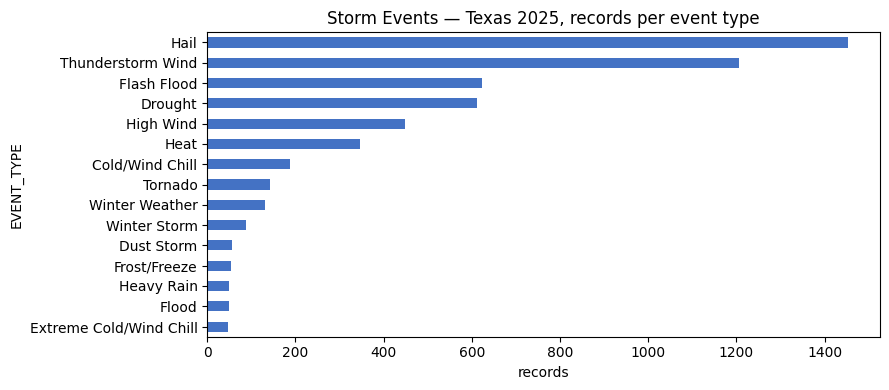

In [4]:
dmg = se.DAMAGE_PROPERTY.map(C.parse_damage)
print("DAMAGE_PROPERTY raw examples:", se.DAMAGE_PROPERTY.dropna().drop_duplicates().head(8).tolist())
print(f"Parsed USD: null {dmg.isna().mean():.1%}, zero {(dmg == 0).mean():.1%}, max {dmg.max():,.0f}")
fig, ax = plt.subplots(figsize=(9, 4))
se.EVENT_TYPE.value_counts().head(15).sort_values().plot.barh(ax=ax, color="#4472c4")
ax.set_title("Storm Events — Texas 2025, records per event type"); ax.set_xlabel("records")
plt.tight_layout(); plt.savefig(FIG / "storm_events_types.png", dpi=150); plt.show()

## 2. H2 — GHCN-Daily through the NCEI Access Data Service (REST/JSON)

One JSON object per station-day. Each element (TMAX, PRCP…) has a companion `<ELEMENT>_ATTRIBUTES`
string `"measurement_flag,quality_flag,source_flag,obs_time"`. `units=metric` returns °C, mm and m/s.

In [5]:
gh_path = latest("ghcn_daily_2*.json")
gh_raw = read_ghcn_daily_json(gh_path)
prof_gh = profile(gh_raw, "GHCN-Daily (10 TX stations)")
prof_gh.sort_values("null_pct", ascending=False)

GHCN-Daily (10 TX stations): 6,747 records x 22 fields


,dtype,null_pct,n_distinct,example
SNWD_ATTRIBUTES,str,1.5,7,",,1"
SNWD,str,1.5,8,0.0
WSF5_ATTRIBUTES,str,0.5,2,",,W"
WSF5,str,0.5,79,8.5
AWND,str,0.2,114,2.9
AWND_ATTRIBUTES,str,0.2,2,",,W"
TMIN_ATTRIBUTES,str,0.1,2,",,W"
WSF2_ATTRIBUTES,str,0.1,2,",,W"
SNOW,str,0.1,20,0.0
WSF2,str,0.1,51,6.7


In [6]:
ELEMS = ["TMAX", "TMIN", "PRCP", "SNOW", "SNWD", "AWND", "WSF2", "WSF5"]
gh = gh_raw.copy()
for e in ELEMS: gh[e] = pd.to_numeric(gh[e], errors="coerce")
gh["DATE"] = pd.to_datetime(gh.DATE)
print("Types as received:", {k: type(v).__name__ for k, v in json.load(open(gh_path))[0].items() if k in ("TMAX", "LATITUDE")})
print("Duplicated (STATION, DATE):", gh.duplicated(["STATION", "DATE"]).sum())
print("Date range:", gh.DATE.min().date(), "->", gh.DATE.max().date())
expected = (gh.DATE.max() - gh.DATE.min()).days + 1
cov = gh.groupby("STATION").DATE.nunique().rename("days").to_frame()
cov["completeness_pct"] = (cov.days / expected * 100).round(1)
display(cov)
display(gh[ELEMS].describe().T.round(1))
for e in ["TMAX", "PRCP", "WSF5"]:
    flags = gh[f"{e}_ATTRIBUTES"].dropna().str.split(",", expand=True)
    print(f"{e}: quality flags {flags[1].replace('', '(blank)').value_counts().to_dict()}  source flags {flags[2].value_counts().to_dict()}")
print("TMIN > TMAX rows:", (gh.TMIN > gh.TMAX).sum())
print("Physically suspicious WSF5 > 60 m/s:"); display(gh.loc[gh.WSF5 > 60, ["STATION", "NAME", "DATE", "WSF5", "WSF5_ATTRIBUTES", "WSF2", "AWND"]])

Types as received: {'TMAX': 'str', 'LATITUDE': 'str'}
Duplicated (STATION, DATE): 0
Date range: 2025-01-01 -> 2026-11-06


,days,completeness_pct
STATION,,
USW00003927,675,100.0
USW00012919,674,99.9
USW00012921,675,100.0
USW00012924,675,100.0
USW00012960,674,99.9
USW00013904,675,100.0
USW00023023,675,100.0
USW00023042,675,100.0
USW00023044,675,100.0


,count,mean,std,min,25%,50%,75%,max
TMAX,6742.0,28.4,8.2,-15.0,24.4,30.0,34.4,42.8
TMIN,6742.0,15.6,9.0,-19.9,9.4,17.8,22.8,30.0
PRCP,6744.0,1.8,7.7,0.0,0.0,0.0,0.0,155.2
SNOW,6743.0,0.2,3.9,0.0,0.0,0.0,0.0,236.0
SNWD,6643.0,0.2,4.3,0.0,0.0,0.0,0.0,178.0
AWND,6735.0,4.5,1.8,0.4,3.1,4.3,5.7,15.1
WSF2,6742.0,9.7,3.0,2.7,7.6,9.4,11.2,36.2
WSF5,6711.0,13.4,4.3,3.6,10.7,13.0,15.6,76.0


TMAX: quality flags {'(blank)': 6742}  source flags {'1': 4365, 'W': 2377}
PRCP: quality flags {'(blank)': 6744}  source flags {'1': 4369, 'W': 2375}
WSF5: quality flags {'(blank)': 6711}  source flags {'1': 4341, 'W': 2370}
TMIN > TMAX rows: 0
Physically suspicious WSF5 > 60 m/s:


,STATION,NAME,DATE,WSF5,WSF5_ATTRIBUTES,WSF2,AWND
3541,USW00023042,"LUBBOCK INTERNATIONAL AIRPORT, TX US",2025-06-17,76.0,",,W",14.8,9.4


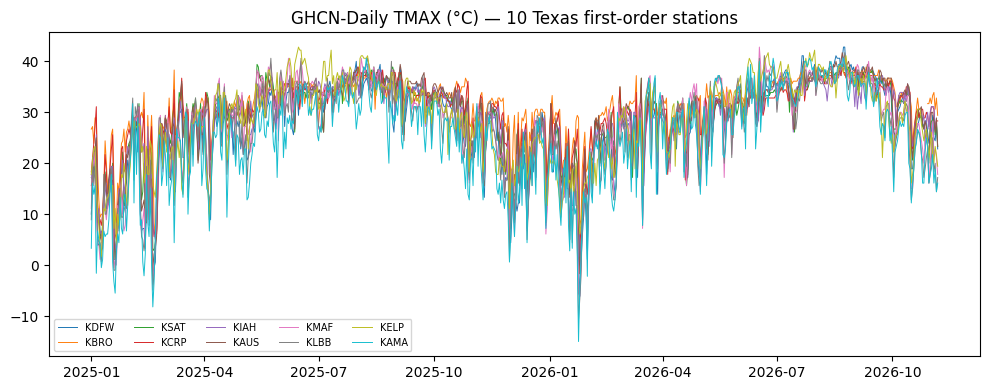

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for st, g in gh.groupby("STATION"):
    ax.plot(g.DATE, g.TMAX, lw=0.7, label=STATIONS.set_index("ghcn_id").loc[st, "nws_id"])
ax.set_title("GHCN-Daily TMAX (°C) — 10 Texas first-order stations"); ax.legend(ncol=5, fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "ghcn_tmax.png", dpi=150); plt.show()

## 3. I1 — NWS Alerts API (GeoJSON, CAP semantics)

In [8]:
POLL1 = SAMPLES / "poll1"
al = read_nws_folder(POLL1, "nws_alerts_recent_*.geojson")
prof_al = profile(al.drop(columns=["geometry"]), "NWS alerts TX (recent, poll 1)")
prof_al.sort_values("null_pct", ascending=False).head(25)

NWS alerts TX (recent, poll 1): 224 records x 36 fields


,dtype,null_pct,n_distinct,example
note,object,100.0,0,NaN
replacedAt,str,54.0,47,2026-11-09T17:02:00-06:00
replacedBy,str,54.0,50,https://api.weather.gov/alerts/urn:oid:2
instruction,str,21.4,61,"Turn around, don't drown when encounteri"
ends,str,19.2,67,2026-11-10T15:00:00-06:00
@type,str,0.0,1,wx:Alert
@id,str,0.0,224,https://api.weather.gov/alerts/urn:oid:2
feature_id,str,0.0,224,https://api.weather.gov/alerts/urn:oid:2
id,str,0.0,224,urn:oid:2.49.0.1.840.0.6e79f59bfb2bd5b63
areaDesc,str,0.0,121,"Mason, TX"


In [9]:
fc = json.load(open(latest("nws_alerts_recent_*.geojson", POLL1), encoding="utf-8"))
print("Pagination object present:", fc.get("pagination"))
print("Duplicated id:", al.id.duplicated().sum())
print("Timestamp examples (local offset, not UTC):", al.sent.iloc[0], "|", al.onset.iloc[0])
print("UTC offsets used in 'sent':", al.sent.str[-6:].value_counts().to_dict())
print(f"Alerts without geometry (zone-based only): {al.geometry.isna().mean():.1%}")
print("messageType:", al.messageType.value_counts().to_dict(), " status:", al.status.value_counts().to_dict())
print("severity:", al.severity.value_counts().to_dict())
print("Alerts with references to earlier messages:", (al.references.map(len) > 0).sum())
display(al.event.value_counts().to_frame("alerts"))

Pagination object present: {'next': 'https://api.weather.gov/alerts?area%5B0%5D=TX&limit=500&cursor=eyJ0IjoxNzkzNjYxODQwLCJpIjoidXJuOm9pZDoyLjQ5LjAuMS44NDAuMC5hZTI2OWNjODUyNDZjMzY5YzE0ZmY5NTRiOWEwYzRjNTJlYmNiMGRhLjAwMS4xIn0%3D'}
Duplicated id: 0
Timestamp examples (local offset, not UTC): 2026-11-09T17:11:00-06:00 | 2026-11-10T00:46:00-06:00
UTC offsets used in 'sent': {'-06:00': 224}
Alerts without geometry (zone-based only): 26.3%
messageType: {'Alert': 119, 'Update': 82, 'Cancel': 23}  status: {'Actual': 224}
severity: {'Severe': 80, 'Minor': 74, 'Moderate': 58, 'Extreme': 12}
Alerts with references to earlier messages: 105


,alerts
event,
Severe Thunderstorm Warning,45
Special Weather Statement,39
Flood Advisory,38
Flash Flood Warning,26
Tornado Watch,14
Flood Warning,12
Coastal Flood Advisory,11
Flood Watch,11
Rip Current Statement,10


## 4. I2 — NWS station observations (GeoJSON, WMO unit codes)

In [10]:
ob = read_nws_folder(POLL1, "nws_observations_*.geojson")
value_cols = [c for c in ob.columns if c.endswith(".value")]
prof_ob = profile(ob[["stationId", "timestamp", "textDescription"] + value_cols], "NWS observations (poll 1)")
prof_ob.sort_values("null_pct", ascending=False)

NWS observations (poll 1): 5,000 records x 20 fields


,dtype,null_pct,n_distinct,example
maxTemperatureLast24Hours.value,object,100.0,0,NaN
minTemperatureLast24Hours.value,object,100.0,0,NaN
precipitationLast3Hours.value,object,99.3,15,0.0
precipitationLast6Hours.value,float64,99.3,19,1.0
precipitationLastHour.value,float64,96.9,36,0.0
windGust.value,float64,96.2,30,29.628
windChill.value,object,89.4,121,7.256583933518889
seaLevelPressure.value,float64,84.9,125,101870.0
heatIndex.value,object,78.6,167,21.64106902380611
windDirection.value,float64,2.9,37,200.0


In [11]:
ob["ts"] = pd.to_datetime(ob.timestamp, utc=True)
span = ob.groupby("stationId").agg(records=("ts", "size"), first=("ts", "min"), last=("ts", "max"))
span["hours_covered"] = ((span["last"] - span["first"]).dt.total_seconds() / 3600).round(1)
display(span)
print("Requested window: 7 days = 168 h. The endpoint silently caps the response at 500 features.")
print("Duplicated (station, timestamp):", ob.duplicated(["stationId", "timestamp"]).sum())
print("Unit codes:", {c: ob[c].dropna().unique().tolist() for c in ob.columns if c.endswith(".unitCode") and c.split(".")[0] in C.NWS_VARIABLES})
print("qualityControl codes (temperature):", ob["temperature.qualityControl"].value_counts().to_dict())
minutes = ob.ts.dt.minute.value_counts().head(6).to_dict(); print("Minute-of-hour distribution (routine :51/:53 vs specials):", minutes)
lon = ob.geometry.map(lambda g: g["coordinates"][0]); lat = ob.geometry.map(lambda g: g["coordinates"][1])
print("Coordinates outside TX bbox:", (~in_bbox(lat, lon)).sum(), "| coordinate decimals:", lat.astype(str).str.split(".").str[1].str.len().max())
print("Keys missing in some features:", sorted(set(ob.columns) - set(ob.dropna(axis=1, how='any').columns))[:12], "...")

,records,first,last,hours_covered
stationId,,,,
KAMA,500,2026-11-05 16:30:00+00:00,2026-11-09 22:45:00+00:00,102.2
KAUS,500,2026-11-05 20:53:00+00:00,2026-11-09 22:45:00+00:00,97.9
KBRO,500,2026-11-06 02:00:00+00:00,2026-11-09 22:45:00+00:00,92.8
KCRP,500,2026-11-06 03:15:00+00:00,2026-11-09 22:45:00+00:00,91.5
KDFW,500,2026-11-05 23:00:00+00:00,2026-11-09 22:45:00+00:00,95.8
KELP,500,2026-11-05 18:51:00+00:00,2026-11-09 23:00:00+00:00,100.2
KIAH,500,2026-11-05 21:35:00+00:00,2026-11-09 22:45:00+00:00,97.2
KLBB,500,2026-11-05 19:40:00+00:00,2026-11-09 22:45:00+00:00,99.1
KMAF,500,2026-11-05 23:40:00+00:00,2026-11-09 23:00:00+00:00,95.3


Requested window: 7 days = 168 h. The endpoint silently caps the response at 500 features.
Duplicated (station, timestamp): 0
Unit codes: {'temperature.unitCode': ['wmoUnit:degC'], 'windSpeed.unitCode': ['wmoUnit:km_h-1'], 'windGust.unitCode': ['wmoUnit:km_h-1'], 'windChill.unitCode': ['wmoUnit:degC'], 'heatIndex.unitCode': ['wmoUnit:degC'], 'precipitationLastHour.unitCode': ['wmoUnit:mm']}
qualityControl codes (temperature): {'V': 4994, 'Z': 6}
Minute-of-hour distribution (routine :51/:53 vs specials): {53: 537, 5: 392, 20: 378, 10: 375, 55: 373, 50: 371}
Coordinates outside TX bbox: 0 | coordinate decimals: 2
Keys missing in some features: ['barometricPressure.value', 'dewpoint.value', 'heatIndex.value', 'icon', 'maxTemperatureLast24Hours.value', 'minTemperatureLast24Hours.value', 'precipitationLast3Hours.value', 'precipitationLast6Hours.qualityControl', 'precipitationLast6Hours.unitCode', 'precipitationLast6Hours.value', 'precipitationLastHour.qualityControl', 'precipitationLastHour

## 5. Canonical mapping applied to every sample

The draft rules (`workshop_1/mapping.md`, implemented in `src/normalization/canonical.py`) are applied
to the four samples to check that every source can fill the canonical `event` fields.

In [12]:
canon = pd.concat([
    C.map_storm_events(se),
    C.map_ghcn_daily(gh_raw),
    C.map_nws_alerts(al),
    C.map_nws_observations(ob.drop(columns=["ts"])),
], ignore_index=True)
summary = canon.groupby("source").agg(
    events=("event_id", "size"), dup_event_id=("event_id", lambda s: s.duplicated().sum()),
    ts_min=("timestamp", "min"), ts_max=("timestamp", "max"),
    lat_null_pct=("latitude", lambda s: round(s.isna().mean() * 100, 1)),
    severity_null_pct=("severity", lambda s: round(s.isna().mean() * 100, 1)),
    units=("severity_unit", lambda s: "; ".join(sorted(s.unique()))[:90]))
summary

,events,dup_event_id,ts_min,ts_max,lat_null_pct,severity_null_pct,units
source,,,,,,,
ghcn_daily,53802,0,2025-01-01 06:00:00+00:00,2026-11-06 07:00:00+00:00,0.0,0.0,degC; m/s; mm
noaa_storm_events,5641,0,2025-01-01 06:00:00+00:00,2025-12-31 10:00:00+00:00,36.7,0.0,"EF scale; impact level 0-3; m/s (wind, EG); m/..."
nws_alerts,224,0,2026-11-02 23:24:00+00:00,2026-11-09 23:11:00+00:00,26.3,0.0,CAP severity 0-4
nws_observations,11803,0,2026-11-05 16:30:00+00:00,2026-11-09 23:00:00+00:00,0.0,0.0,degC; m/s; mm


In [13]:
canon.sample(8, random_state=3)

,event_id,source,event_type,timestamp,latitude,longitude,severity,severity_unit,raw_reference,content_hash
57168,ghcn_daily:USW00023047:2026-02-24:WSF5,ghcn_daily,daily_fastest_5s_wind,2026-02-24 06:00:00+00:00,35.22027,-101.71733,13.9,m/s,USW00023047/2026-02-24/WSF5,88475f6c111d764604588144d4a156a52b9876e8db51f7...
63275,nws_observations:KLBB:2026-11-08T23:55:00+00:0...,nws_observations,air_temperature,2026-11-08 23:55:00+00:00,33.65000,-101.82000,13.0,degC,https://api.weather.gov/stations/KLBB/observat...,8d70afa3fb631b1960a47715fe1a98ea9f53a4008ac5b1...
22753,ghcn_daily:USW00023042:2025-09-14:PRCP,ghcn_daily,daily_precipitation,2025-09-14 06:00:00+00:00,33.66578,-101.82330,22.1,mm,USW00023042/2025-09-14/PRCP,a2ea2289285a9ae652fe24fac552ad5547421ba65ae69a...
57734,ghcn_daily:USW00012924:2025-11-07:WSF5,ghcn_daily,daily_fastest_5s_wind,2025-11-07 06:00:00+00:00,27.77335,-97.51302,12.5,m/s,USW00012924/2025-11-07/WSF5,d43fb9c1133f8f7f2a2ef3a63728b7ec734e86a7dee5eb...
48379,ghcn_daily:USW00012921:2026-01-02:WSF2,ghcn_daily,daily_fastest_2min_wind,2026-01-02 06:00:00+00:00,29.54429,-98.48395,7.6,m/s,USW00012921/2026-01-02/WSF2,70c5369bb179f1290a04d207c89ef64e3fd410a586c790...
57180,ghcn_daily:USW00023047:2026-03-08:WSF5,ghcn_daily,daily_fastest_5s_wind,2026-03-08 06:00:00+00:00,35.22027,-101.71733,18.8,m/s,USW00023047/2026-03-08/WSF5,f38ddf6007341b727fdff17e1280ed0f9ddee6c79f1559...
36111,ghcn_daily:USW00023042:2025-07-19:SNWD,ghcn_daily,snow_depth,2025-07-19 06:00:00+00:00,33.66578,-101.82330,0.0,mm,USW00023042/2025-07-19/SNWD,a0e9e114cc000646c70986aba32e756f8687cf3f4cf5c2...
42805,ghcn_daily:USW00023042:2025-07-02:AWND,ghcn_daily,daily_mean_wind_speed,2025-07-02 06:00:00+00:00,33.66578,-101.82330,3.7,m/s,USW00023042/2025-07-02/AWND,6f2af6b9db54eb24eb783b781448968a2a7bf247b3b69b...


## 6. Data-quality problems found (with example records)

In [14]:
issues = []
ex = se[se.BEGIN_LAT.isna()].iloc[0]
issues.append(("H1 Storm Events", "No coordinates for zone/county-based events",
               f"{pd.to_numeric(se.BEGIN_LAT).isna().mean():.1%} of rows", f"EVENT_ID {ex.EVENT_ID}: {ex.EVENT_TYPE}, CZ_TYPE={ex.CZ_TYPE}, CZ_NAME={ex.CZ_NAME}, BEGIN_LAT=NaN"))
ex = se.iloc[0]
issues.append(("H1 Storm Events", "Local standard time + 2-digit year in BEGIN_DATE_TIME",
               "all rows", f"EVENT_ID {ex.EVENT_ID}: BEGIN_DATE_TIME='{ex.BEGIN_DATE_TIME}', CZ_TIMEZONE='{ex.CZ_TIMEZONE}'"))
ex = se[se.DAMAGE_PROPERTY.fillna('').str.contains('[KM]', regex=True) & (se.DAMAGE_PROPERTY != '0.00K')].iloc[0]
issues.append(("H1 Storm Events", "Damage stored as text with K/M/B suffix; blanks mean 'unknown', not 0",
               f"{se.DAMAGE_PROPERTY.isna().mean():.1%} blank", f"EVENT_ID {ex.EVENT_ID}: DAMAGE_PROPERTY='{ex.DAMAGE_PROPERTY}'"))
h = se[se.EVENT_TYPE == 'Hail'].iloc[0]; w = se[se.EVENT_TYPE == 'Thunderstorm Wind'].dropna(subset=['MAGNITUDE']).iloc[0]
issues.append(("H1 Storm Events", "MAGNITUDE has different units per event type (hail inches, wind knots; EG=estimated vs MG=measured)",
               "Hail/Wind rows", f"EVENT_ID {h.EVENT_ID} Hail MAGNITUDE={h.MAGNITUDE} (in); EVENT_ID {w.EVENT_ID} TSTM Wind MAGNITUDE={w.MAGNITUDE} {w.MAGNITUDE_TYPE} (kt)"))
z = se[(se.CZ_TYPE == 'Z')].iloc[0]
issues.append(("H1 Storm Events", "CZ_FIPS of forecast zones (Z) is a zone number, not a county FIPS; names vary ('INLAND HARRIS')",
               f"{(se.CZ_TYPE == 'Z').mean():.1%} of rows", f"EVENT_ID {z.EVENT_ID}: CZ_TYPE=Z, CZ_FIPS={z.CZ_FIPS}, CZ_NAME={z.CZ_NAME}"))
raw_gz = sorted((ROOT / "data" / "raw").glob("noaa_storm_events_*.csv.gz"))
if raw_gz:  # full US file (git-ignored); re-download with fetch_samples.py historical
    full = read_storm_events(raw_gz[-1])
    text_hit = full[(full == "TEXAS").any(axis=1)]
    wrong = text_hit[text_hit.STATE_FIPS != "48"]
    w = wrong.iloc[0]
    issues.append(("H1 Storm Events", "Filtering by the text 'TEXAS' also matches Texas County (MO, OK) and other states' fields; filter must use STATE_FIPS=48",
                   f"{len(wrong)} wrong rows ({', '.join(f'{k}: {v}' for k, v in wrong.STATE.value_counts().items())})",
                   f"EVENT_ID {w.EVENT_ID}: STATE={w.STATE}, CZ_NAME={w.CZ_NAME}, TOR_OTHER_CZ_NAME={w.TOR_OTHER_CZ_NAME}"))
o = gh.loc[gh.WSF5.idxmax()]
issues.append(("H2 GHCN-Daily", "Implausible wind gust value not flagged by QC",
               "1+ rows", f"{o.STATION} {o.DATE.date()}: WSF5={o.WSF5} m/s (~{o.WSF5/C.KNOT_TO_MS:.0f} kt), attributes='{o.WSF5_ATTRIBUTES}'"))
miss = gh_raw[gh_raw.WSF5.isna()].iloc[0]
issues.append(("H2 GHCN-Daily", "Missing elements are absent keys (not null); numbers arrive as strings",
               f"WSF5 absent in {gh_raw.WSF5.isna().mean():.1%}", f"{miss.STATION} {miss.DATE}: keys without WSF5; TMAX='{miss.TMAX}' (str)"))
issues.append(("H2 GHCN-Daily", "Latency: most recent days not yet published",
               f"last DATE {gh.DATE.max().date()}", f"query endDate = download date; last available = {gh.DATE.max().date()}"))
a = al[al.geometry.isna()].iloc[0]
issues.append(("I1 NWS alerts", "Alerts without polygon geometry (only UGC zone codes)",
               f"{al.geometry.isna().mean():.1%}", f"{a.id[-20:]}: event={a.event}, geometry=None, UGC={a.geocode['UGC'][:3]}"))
issues.append(("I1 NWS alerts", "Timestamps carry local offsets (-05:00/-06:00/-07:00), not UTC",
               "all rows", f"sent='{al.sent.iloc[0]}'"))
c = span.hours_covered.min()
issues.append(("I2 NWS observations", "Silent 500-feature cap truncates the requested 7-day window",
               f"every station (min {c} h of 168 h)", f"KDFW: {span.loc['KDFW','records']} records from {span.loc['KDFW','first']} to {span.loc['KDFW','last']}"))
g0 = ob[ob['windGust.value'].isna()].iloc[0]
issues.append(("I2 NWS observations", "Nulls encoded as value=None with qualityControl='Z'; some keys absent",
               f"windGust null {ob['windGust.value'].isna().mean():.0%}", f"{g0.stationId} {g0.timestamp}: windGust={{'value': None, 'qualityControl': '{g0['windGust.qualityControl']}'}}"))
dq = pd.DataFrame(issues, columns=["source", "problem", "extent", "example record"])
dq.to_csv(ROOT / "workshop_1" / "data_quality_issues.csv", index=False)
dq

,source,problem,extent,example record
0,H1 Storm Events,No coordinates for zone/county-based events,36.7% of rows,"EVENT_ID 1230373: Coastal Flood, CZ_TYPE=Z, CZ..."
1,H1 Storm Events,Local standard time + 2-digit year in BEGIN_DA...,all rows,EVENT_ID 1230373: BEGIN_DATE_TIME='09-JAN-25 2...
2,H1 Storm Events,Damage stored as text with K/M/B suffix; blank...,15.7% blank,EVENT_ID 1256818: DAMAGE_PROPERTY='10.00K'
3,H1 Storm Events,MAGNITUDE has different units per event type (...,Hail/Wind rows,EVENT_ID 1230425 Hail MAGNITUDE=1.00 (in); EVE...
4,H1 Storm Events,CZ_FIPS of forecast zones (Z) is a zone number...,36.7% of rows,"EVENT_ID 1230373: CZ_TYPE=Z, CZ_FIPS=338, CZ_N..."
5,H1 Storm Events,Filtering by the text 'TEXAS' also matches Tex...,"66 wrong rows (MISSOURI: 34, OKLAHOMA: 31, MAR...","EVENT_ID 1251602: STATE=MISSOURI, CZ_NAME=TEXA..."
6,H2 GHCN-Daily,Implausible wind gust value not flagged by QC,1+ rows,USW00023042 2025-06-17: WSF5=76.0 m/s (~148 kt...
7,H2 GHCN-Daily,Missing elements are absent keys (not null); n...,WSF5 absent in 0.5%,USW00003927 2025-03-09: keys without WSF5; TMA...
8,H2 GHCN-Daily,Latency: most recent days not yet published,last DATE 2026-11-06,query endDate = download date; last available ...
9,I1 NWS alerts,Alerts without polygon geometry (only UGC zone...,26.3%,d7bcdd5771c0a3.002.1: event=Coastal Flood Advi...


## 7. Cross-source overlap — candidate pairs describing the same real-world event

Rule used for the candidates (to be refined in Workshop 3): Storm Events record in the **county
of a station** (exact `CZ_FIPS` for county rows, word-boundary name match for zone rows) and on
the **same local calendar day** as the GHCN-Daily record, with a compatible variable
(hail/wind ↔ WSF5, flood/rain ↔ PRCP, heat ↔ TMAX, cold ↔ TMIN, winter ↔ SNOW).

In [15]:
STATION_COUNTY = {"USW00003927": ("TARRANT", "439"), "USW00012960": ("HARRIS", "201"), "USW00013904": ("TRAVIS", "453"),
    "USW00012921": ("BEXAR", "029"), "USW00023044": ("EL PASO", "141"), "USW00023042": ("LUBBOCK", "303"),
    "USW00023047": ("POTTER", "375"), "USW00012924": ("NUECES", "355"), "USW00023023": ("MIDLAND", "329"),
    "USW00012919": ("CAMERON", "061")}
VAR = {"Thunderstorm Wind": "WSF5", "High Wind": "WSF5", "Hail": "WSF5", "Flash Flood": "PRCP", "Heavy Rain": "PRCP",
       "Heat": "TMAX", "Excessive Heat": "TMAX", "Extreme Cold/Wind Chill": "TMIN", "Cold/Wind Chill": "TMIN",
       "Winter Storm": "SNOW", "Frost/Freeze": "TMIN"}
se2 = se.copy(); se2["local_date"] = pd.to_datetime(se2.BEGIN_YEARMONTH + se2.BEGIN_DAY.str.zfill(2))
pairs = []
for st, (name, fips) in STATION_COUNTY.items():
    m_c = (se2.CZ_TYPE == "C") & (se2.CZ_FIPS.str.zfill(3) == fips)
    m_z = (se2.CZ_TYPE == "Z") & se2.CZ_NAME.str.contains(rf"\b{name}\b", regex=True)
    cand = se2[(m_c | m_z) & se2.EVENT_TYPE.isin(VAR)].merge(gh[gh.STATION == st], left_on="local_date", right_on="DATE")
    pairs.append(cand)
pairs = pd.concat(pairs)
pairs["ghcn_var"] = pairs.EVENT_TYPE.map(VAR)
pairs["ghcn_value"] = [r[v] for r, v in zip(pairs.to_dict("records"), pairs.ghcn_var)]
pairs["se_value_SI"] = [C.storm_event_severity(r)[0] if r["EVENT_TYPE"] in ("Hail", "Thunderstorm Wind", "High Wind") else np.nan
                        for _, r in pairs.iterrows()]
cols = ["EVENT_ID", "EVENT_TYPE", "CZ_TYPE", "CZ_NAME", "BEGIN_DATE_TIME", "CZ_TIMEZONE", "MAGNITUDE", "MAGNITUDE_TYPE", "se_value_SI",
        "STATION", "DATE", "ghcn_var", "ghcn_value"]
print("Candidate pairs found:", len(pairs))
best = (pairs.sort_values("ghcn_value", ascending=False).groupby("EVENT_TYPE").head(1))
best[cols].reset_index(drop=True)

Candidate pairs found: 471


,EVENT_ID,EVENT_TYPE,CZ_TYPE,CZ_NAME,BEGIN_DATE_TIME,CZ_TIMEZONE,MAGNITUDE,MAGNITUDE_TYPE,se_value_SI,STATION,DATE,ghcn_var,ghcn_value
0,1272279,Flash Flood,C,BEXAR,12-JUN-25 01:15:00,CST-6,NaN,NaN,NaN,USW00012921,2025-06-12,PRCP,155.2
1,1246058,Winter Storm,Z,POTTER,08-MAR-25 19:00:00,CST-6,NaN,NaN,NaN,USW00023047,2025-03-08,SNOW,102.0
2,1271694,Thunderstorm Wind,C,LUBBOCK,17-JUN-25 18:19:00,CST-6,50.00,MG,25.722200,USW00023042,2025-06-17,WSF5,76.0
3,1271692,Hail,C,LUBBOCK,17-JUN-25 18:10:00,CST-6,1.25,NaN,31.750000,USW00023042,2025-06-17,WSF5,76.0
4,1294685,Heavy Rain,C,EL PASO,19-SEP-25 20:13:00,MST-7,NaN,NaN,NaN,USW00023044,2025-09-19,PRCP,49.5
5,1246090,High Wind,Z,POTTER,14-MAR-25 05:46:00,CST-6,72.00,MG,37.039968,USW00023047,2025-03-14,WSF5,37.1
6,1287962,Heat,Z,TARRANT,24-JUL-25 11:00:00,CST-6,NaN,NaN,NaN,USW00003927,2025-07-24,TMAX,36.7
7,1231305,Cold/Wind Chill,Z,CAMERON,20-JAN-25 23:30:00,CST-6,NaN,NaN,NaN,USW00012919,2025-01-20,TMIN,6.7
8,1235787,Frost/Freeze,Z,INLAND NUECES COUNTY,07-JAN-25 03:00:00,CST-6,NaN,NaN,NaN,USW00012924,2025-01-07,TMIN,1.7
9,1233513,Extreme Cold/Wind Chill,Z,TARRANT,18-FEB-25 22:00:00,CST-6,NaN,NaN,NaN,USW00003927,2025-02-18,TMIN,-7.1


**Second overlap: NWS observations ↔ GHCN-Daily.** First-order stations are published by both
services (same ASOS sensor). The daily maximum of the NWS hourly temperatures should match GHCN
`TMAX` for the overlapping days, but only after converting UTC timestamps to the station's
local standard day (UTC-6 / UTC-7), which is the GHCN-Daily day definition at these stations.

In [16]:
o2 = ob.merge(STATIONS, left_on="stationId", right_on="nws_id")
o2["lst_offset"] = o2.ghcn_id.map(C.STATION_LST).fillna(-6)
o2["local_day"] = (o2.ts + pd.to_timedelta(o2.lst_offset, unit="h")).dt.tz_localize(None).dt.normalize()
o2["utc_day"] = o2.ts.dt.tz_localize(None).dt.normalize()
o2["local_hour"] = (o2.ts + pd.to_timedelta(o2.lst_offset, unit="h")).dt.hour
agg_lst = o2.groupby(["ghcn_id", "nws_id", "local_day"]).agg(
    max=("temperature.value", "max"), size=("ts", "size"), first_hour=("local_hour", "min"), last_hour=("local_hour", "max")).reset_index()
cmp = agg_lst.merge(gh[["STATION", "DATE", "TMAX"]], left_on=["ghcn_id", "local_day"], right_on=["STATION", "DATE"])
partial = cmp[(cmp.first_hour > 0) | (cmp.last_hour < 23)]
print(f"Partial days excluded (500-record cap starts mid-day): {len(partial)}")
cmp = cmp[(cmp.first_hour == 0) & (cmp.last_hour == 23)]  # complete local days only
agg_utc = o2.groupby(["ghcn_id", "utc_day"])["temperature.value"].max().rename("max_utc_day").reset_index()
cmp = cmp.merge(agg_utc, left_on=["ghcn_id", "local_day"], right_on=["ghcn_id", "utc_day"], how="left")
cmp["diff_lst"] = (cmp["max"] - cmp.TMAX).round(1); cmp["diff_utc_day"] = (cmp.max_utc_day - cmp.TMAX).round(1)
print(f"Station-days compared: {len(cmp)};  mean |diff| local-standard-day = {cmp.diff_lst.abs().mean():.2f} °C,  using UTC day = {cmp.diff_utc_day.abs().mean():.2f} °C")
cmp[["nws_id", "local_day", "size", "max", "TMAX", "diff_lst", "max_utc_day", "diff_utc_day"]].head(12)

Partial days excluded (500-record cap starts mid-day): 10
Station-days compared: 9;  mean |diff| local-standard-day = 0.11 °C,  using UTC day = 0.22 °C


,nws_id,local_day,size,max,TMAX,diff_lst,max_utc_day,diff_utc_day
0,KDFW,2026-11-06,137,23.0,22.8,0.2,24.0,1.2
1,KBRO,2026-11-06,126,29.4,29.4,0.0,29.4,0.0
2,KSAT,2026-11-06,138,23.3,23.3,0.0,23.3,0.0
3,KCRP,2026-11-06,126,28.0,28.3,-0.3,28.0,-0.3
4,KAUS,2026-11-06,120,23.3,23.3,0.0,23.3,0.0
5,KMAF,2026-11-06,139,18.0,17.8,0.2,18.0,0.2
6,KLBB,2026-11-06,125,17.0,17.2,-0.2,17.0,-0.2
7,KELP,2026-11-06,132,19.4,19.4,0.0,19.4,0.0
8,KAMA,2026-11-06,114,16.0,16.1,-0.1,16.0,-0.1


**Third overlap: NWS alerts ↔ NWS alerts (same event, several messages).** An `Update` or `Cancel`
message references the original alert id(s) in `properties.references`; these chains are the
event-identification problem inside the alert source itself.

In [17]:
ids = set(al.id)
chains = al[al.references.map(len) > 0].copy()
chains["refs_in_sample"] = chains.references.map(lambda refs: sum(r["identifier"] in ids for r in refs))
chains[["id", "event", "messageType", "sent", "refs_in_sample"]].assign(id=lambda d: d.id.str[-26:]).head(8)

,id,event,messageType,sent,refs_in_sample
2,779b4f7cd8516dd7d626.001.1,Flood Warning,Update,2026-11-09T17:02:00-06:00,1
5,a51d280407f03197d546.001.1,Flood Advisory,Update,2026-11-09T13:27:00-06:00,1
6,118a34964a4a04b363d4.001.1,Flood Advisory,Update,2026-11-09T13:26:00-06:00,1
9,aff882d7bcdd5771c0a3.002.1,Coastal Flood Advisory,Update,2026-11-09T11:57:00-06:00,2
10,aff882d7bcdd5771c0a3.001.2,Rip Current Statement,Update,2026-11-09T11:57:00-06:00,2
11,aff882d7bcdd5771c0a3.001.1,Coastal Flood Advisory,Update,2026-11-09T11:57:00-06:00,2
12,5434be7769932ce7b305.001.1,Flood Watch,Update,2026-11-09T11:52:00-06:00,1
15,a022bb99a572f5b0163e.001.1,Flash Flood Warning,Cancel,2026-11-09T09:48:00-06:00,2


## 8. Incremental behaviour — two polls at least one hour apart

`fetch_samples.py incremental pollN` was executed twice (poll 1 and poll 2). We compare identifiers,
content hashes and HTTP caching headers to learn how new and changed records can be detected.

In [18]:
POLL2 = SAMPLES / "poll2"
if not POLL2.exists():
    print("poll2 not available yet")
else:
    def headers(folder, pattern):
        return json.load(open(sorted(Path(folder).glob(pattern + ".headers.json"))[-1]))
    for pat in ["nws_alerts_active_*", "nws_observations_KDFW_*"]:
        h1, h2 = headers(POLL1, pat), headers(POLL2, pat)
        print(pat, "\n  poll1:", h1["retrieved_utc"], h1["headers"], "\n  poll2:", h2["retrieved_utc"], h2["headers"])

    act1 = read_nws_folder(POLL1, "nws_alerts_active_*.geojson"); act2 = read_nws_folder(POLL2, "nws_alerts_active_*.geojson")
    rec1 = read_nws_folder(POLL1, "nws_alerts_recent_*.geojson"); rec2 = read_nws_folder(POLL2, "nws_alerts_recent_*.geojson")
    s1, s2 = set(act1.get("id", [])), set(act2.get("id", []))
    print(f"\nACTIVE alerts: poll1={len(s1)} poll2={len(s2)} new={len(s2 - s1)} no-longer-active={len(s1 - s2)} kept={len(s1 & s2)}")
    r1, r2 = set(rec1.id), set(rec2.id)
    print(f"RECENT alerts: poll1={len(r1)} poll2={len(r2)} new={len(r2 - r1)} dropped-from-window={len(r1 - r2)}")
    common = r1 & r2
    h = lambda df: dict(zip(df.id, [C.content_hash(r) for r in df.drop(columns=['raw_file']).to_dict('records')]))
    hh1, hh2 = h(rec1), h(rec2)
    print("Recent alerts whose content changed between polls (same id):", sum(hh1[i] != hh2[i] for i in common))
    new_al = rec2[rec2.id.isin(r2 - r1)]
    print("New alerts by messageType:", new_al.messageType.value_counts().to_dict(), " max sent poll1:", rec1.sent.max(), " poll2:", rec2.sent.max())

    ob2 = read_nws_folder(POLL2, "nws_observations_*.geojson")
    k1 = ob.set_index(["stationId", "timestamp"]); k2 = ob2.set_index(["stationId", "timestamp"])
    new_keys = k2.index.difference(k1.index); same = k2.index.intersection(k1.index)
    vc = [c for c in value_cols if c in k2.columns]
    changed = (k1.loc[same, vc].fillna(-9999).ne(k2.loc[same, vc].fillna(-9999))).any(axis=1)
    print(f"\nOBSERVATIONS: poll1={len(k1)} poll2={len(k2)} new (station,timestamp)={len(new_keys)} revised existing={changed.sum()}")
    print("Max timestamp per station poll1 vs poll2:")
    display(pd.DataFrame({"poll1": ob.groupby("stationId").timestamp.max(), "poll2": ob2.groupby("stationId").timestamp.max()}))
    if changed.any():
        i = changed[changed].index[0]
        diff = pd.DataFrame({"poll1": k1.loc[i, vc], "poll2": k2.loc[i, vc]}); display(diff[diff.poll1.fillna(-9999) != diff.poll2.fillna(-9999)])

nws_alerts_active_* 
  poll1: 20261109_232218 {'Content-Type': 'application/geo+json', 'ETag': 'W/"0aba9408137237a9c7a633c9848b5192"', 'X-Correlation-ID': '30a9f40', 'Content-Length': '7241', 'Cache-Control': 'public, max-age=5, s-maxage=5', 'Expires': 'Mon, 09 Nov 2026 23:22:35 GMT', 'Date': 'Mon, 09 Nov 2026 23:22:30 GMT'} 
  poll2: 20261110_002450 {'Content-Type': 'application/geo+json', 'ETag': 'W/"b2477b055f8fac217e56fa4dff845fe6"', 'X-Correlation-ID': '28106adc', 'Content-Length': '6486', 'Cache-Control': 'public, max-age=5, s-maxage=5', 'Expires': 'Tue, 10 Nov 2026 00:24:59 GMT', 'Date': 'Tue, 10 Nov 2026 00:24:54 GMT'}
nws_observations_KDFW_* 
  poll1: 20261109_232218 {'Content-Type': 'application/geo+json', 'X-Correlation-ID': '27a4aa1a', 'Content-Length': '39613', 'Cache-Control': 'public, max-age=300, s-maxage=120', 'Expires': 'Mon, 09 Nov 2026 23:27:32 GMT', 'Date': 'Mon, 09 Nov 2026 23:22:32 GMT'} 
  poll2: 20261110_002450 {'Content-Type': 'application/geo+json', 'X-Correl


OBSERVATIONS: poll1=5000 poll2=5000 new (station,timestamp)=38 revised existing=0
Max timestamp per station poll1 vs poll2:


,poll1,poll2
stationId,,
KAMA,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KAUS,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KBRO,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KCRP,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KDFW,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KELP,2026-11-09T23:00:00+00:00,2026-11-10T00:05:00+00:00
KIAH,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KLBB,2026-11-09T22:45:00+00:00,2026-11-09T23:55:00+00:00
KMAF,2026-11-09T23:00:00+00:00,2026-11-10T00:05:00+00:00


## 9. Historical volume estimate and partitioning

In [19]:
listing = (sorted(SAMPLES.glob("noaa_storm_events_listing_*.html"))[-1]).read_text(encoding="utf-8")
rows = re.findall(r'>(StormEvents_details-ftp_v1\.0_d(\d{4})_c(\d{8})\.csv\.gz)</a></td>\s*<td[^>]*>([^<]+)</td>\s*<td[^>]*>(\d+)</td>', listing)
sizes = pd.DataFrame(rows, columns=["file", "year", "compiled", "modified", "bytes"]).astype({"year": int, "bytes": int})
sizes = sizes[sizes.year >= 2010]
sizes["MB_gz"] = (sizes.bytes / 2**20).round(1)
display(sizes[["year", "compiled", "modified", "MB_gz"]].set_index("year").T)
tx_per_year = len(se)
gh_rows_year = len(gh) / ((gh.DATE.max() - gh.DATE.min()).days / 365.25)
obs_per_day = (span.records / (span.hours_covered / 24)).mean()
vol = pd.DataFrame([
    ["H1 Storm Events (TX, 2010-2026)", f"{len(sizes)} yearly files, {sizes.MB_gz.sum():.0f} MB gz (US-wide)", f"~{tx_per_year * len(sizes):,.0f} TX rows", "1 file per year"],
    ["H2 GHCN-Daily (10 stations, 2010-2026)", f"~{gh_path.stat().st_size / 2**20 / ((gh.DATE.max()-gh.DATE.min()).days/365.25) * 17:.0f} MB JSON", f"~{gh_rows_year * 17:,.0f} station-days (x8 elements)", "1 request per station-year (170 requests)"],
    ["I1 NWS alerts (TX)", "~1.4 MB per week", f"~{len(al) * 52:,} alerts/year", "cursor pagination, poll every 15 min"],
    ["I2 NWS observations (10 stations)", "~2 MB per station per 500 obs", f"~{obs_per_day * 10 * 365:,.0f} obs/year", "per station, start=watermark-overlap"],
], columns=["source", "size", "rows", "partitioning"])
vol

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
compiled,20260323,20260323,20261026,20260323,20260323,20260323,20260323,20260519,20260323,20260323,20260323,20260323,20260625,20260323,20260728,20260819,20261026
modified,2026-03-23 13:10,2026-03-23 13:10,2026-10-26 12:56,2026-03-23 13:10,2026-03-23 13:10,2026-03-23 13:10,2026-03-23 13:10,2026-05-19 11:22,2026-03-23 13:10,2026-03-23 13:10,2026-03-23 13:24,2026-03-23 13:10,2026-06-25 14:39,2026-03-23 13:10,2026-07-27 21:11,2026-08-19 18:22,2026-10-26 12:57
MB_gz,11.2,15.0,14.1,11.2,10.6,9.6,8.6,8.9,9.1,11.1,10.0,10.1,11.3,12.3,12.1,12.0,8.8


,source,size,rows,partitioning
0,"H1 Storm Events (TX, 2010-2026)","17 yearly files, 186 MB gz (US-wide)","~95,897 TX rows",1 file per year
1,"H2 GHCN-Daily (10 stations, 2010-2026)",~28 MB JSON,"~62,157 station-days (x8 elements)",1 request per station-year (170 requests)
2,I1 NWS alerts (TX),~1.4 MB per week,"~11,648 alerts/year","cursor pagination, poll every 15 min"
3,I2 NWS observations (10 stations),~2 MB per station per 500 obs,"~455,290 obs/year","per station, start=watermark-overlap"
